# Data Comparing

Jupiter Notebook to compare result from different calculations

In [12]:
import matplotlib.pyplot as plt
plt.rcParams.update({
    'figure.figsize': (6.5, 4.3),
    'font.family': 'times new roman',
    'mathtext.fontset': 'cm',
    'axes.titlesize': 14,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'font.size': 14,
    'legend.fontsize': 12,
    'legend.loc': 'best',
    'legend.fancybox': False,
    'legend.shadow': False,
    'legend.frameon': True,
    'figure.dpi': 500,
    'text.usetex': False,
    'lines.markersize': 8,
    'lines.linewidth': 3,
    'lines.markeredgewidth': 1,
    'lines.markeredgecolor': 'black',
    'scatter.edgecolors': 'black',
    'patch.edgecolor': 'black',
    'axes.prop_cycle': plt.cycler(color =['cyan', 'red', 'green', 'blue', 'magenta', 'yellow', 'black']),
})

## Usage examples

### Example 1: Quasi-static solution for periodic structure

There is base usage case for modeling using direct solver with matrix equation solving with inductance for thin rings.

In [5]:
from Metastructure import Metastructure
from Solvers import MetaSolver, MetaSolution
# import default parameters for rings from file 
from Parameters import SRR, Omega

import numpy as np
import matplotlib.pyplot as plt

# Creating example metastructure 
# Size of cube in number of metacell
nz, ny, nx = 4, 4, 4
# Type is 'smooth' or 'ragged' or 'centred' or 'anizotropic'
# Geometry is 'ellipsoid' or 'rectangle' or 'cylinder-z' or 'cylinder-y' or 'cylinder-x'
Type, geometry = 'smooth', 'rectangle'  # 'smooth' or 'ragged'
MetaCube = Metastructure(metamaterial = SRR,	# Metaatom parameters
						 shape = (nz, ny, nx), 	# Size for uniform grid
						 geometry=geometry,  	# form of the structure
						 Type = Type, 		# type of finite metastructure
)
MetaCube.fill_grid()
# Draw 3D visualization before solving 
MetaCube.visualize()

In [6]:
# Create solver for chosen metastructure
solver = MetaSolver(Omega = Omega,
					metastructure = MetaCube)
print(solver.number, "rings in the solver")
# Create uniform excitation
U_z = np.ones(MetaCube.numbers['z'])
U_y = np.zeros(MetaCube.numbers['y'])
U_x = np.zeros(MetaCube.numbers['x'])
U = np.concatenate([U_z, U_y, U_x])
# Calculate solution on given frequency range
solution = solver.direct_solve(U)
# Save solution to folder './Data'
solution.save_sol('./Data')

240 rings in the solver
Calculating Inductance Matrix:


100%|██████████| 240/240 [00:00<00:00, 393.20it/s]


Direct solving (Currents)


100%|██████████| 1000/1000 [00:01<00:00, 731.54it/s]


Direct solving (Currents): Done


In [7]:
# Solve for polarizability along z-axis
print(solver.number, "rings in the solver")
# Calculate solution on given frequency range
solution = solver.direct_polarizability(axes='z')
# Save solution to folder './Data'
solution.save_sol('./DataPolarizability')

240 rings in the solver
Calculating Inductance Matrix:


100%|██████████| 240/240 [00:00<00:00, 9044.00it/s]


Direct solving (Currents)


100%|██████████| 1000/1000 [00:01<00:00, 767.32it/s]

Direct solving (Currents): Done


### Example 2: Quasi-static solution for custom configuration

There is case for non-periodic structures with direct solver. If there is many calculations for same geometry (for example for different frequencie or self impedances) there is possibility to save inductance matrix to avoid extra integral calculations. 

In [ ]:
from Solvers import MetaSolver, MetaSolution
# import default parameters for rings from file 
from Parameters import SRR, Omega
from Metamaterial import Ring, visualize_rings

import numpy as np
import matplotlib.pyplot as plt

# Creating some random rings 

rings = []
for i in range(7):
	x, y, z = np.random.uniform(-0.02, 0.02, 3)
	ring = Ring(x, y, z, 'z', SRR.radius, SRR.width, SRR.R, SRR.L, SRR.C)
	rings.append(ring)
print(f"Created {len(rings)} rings.")
visualize_rings(rings)

Created 7 rings.


7 rings in the solver
Calculating Inductance Matrix:


100%|██████████| 7/7 [00:00<00:00, 625.88it/s]


Direct solving (Currents)


100%|██████████| 1000/1000 [00:00<00:00, 50137.52it/s]


Direct solving (Currents): Done


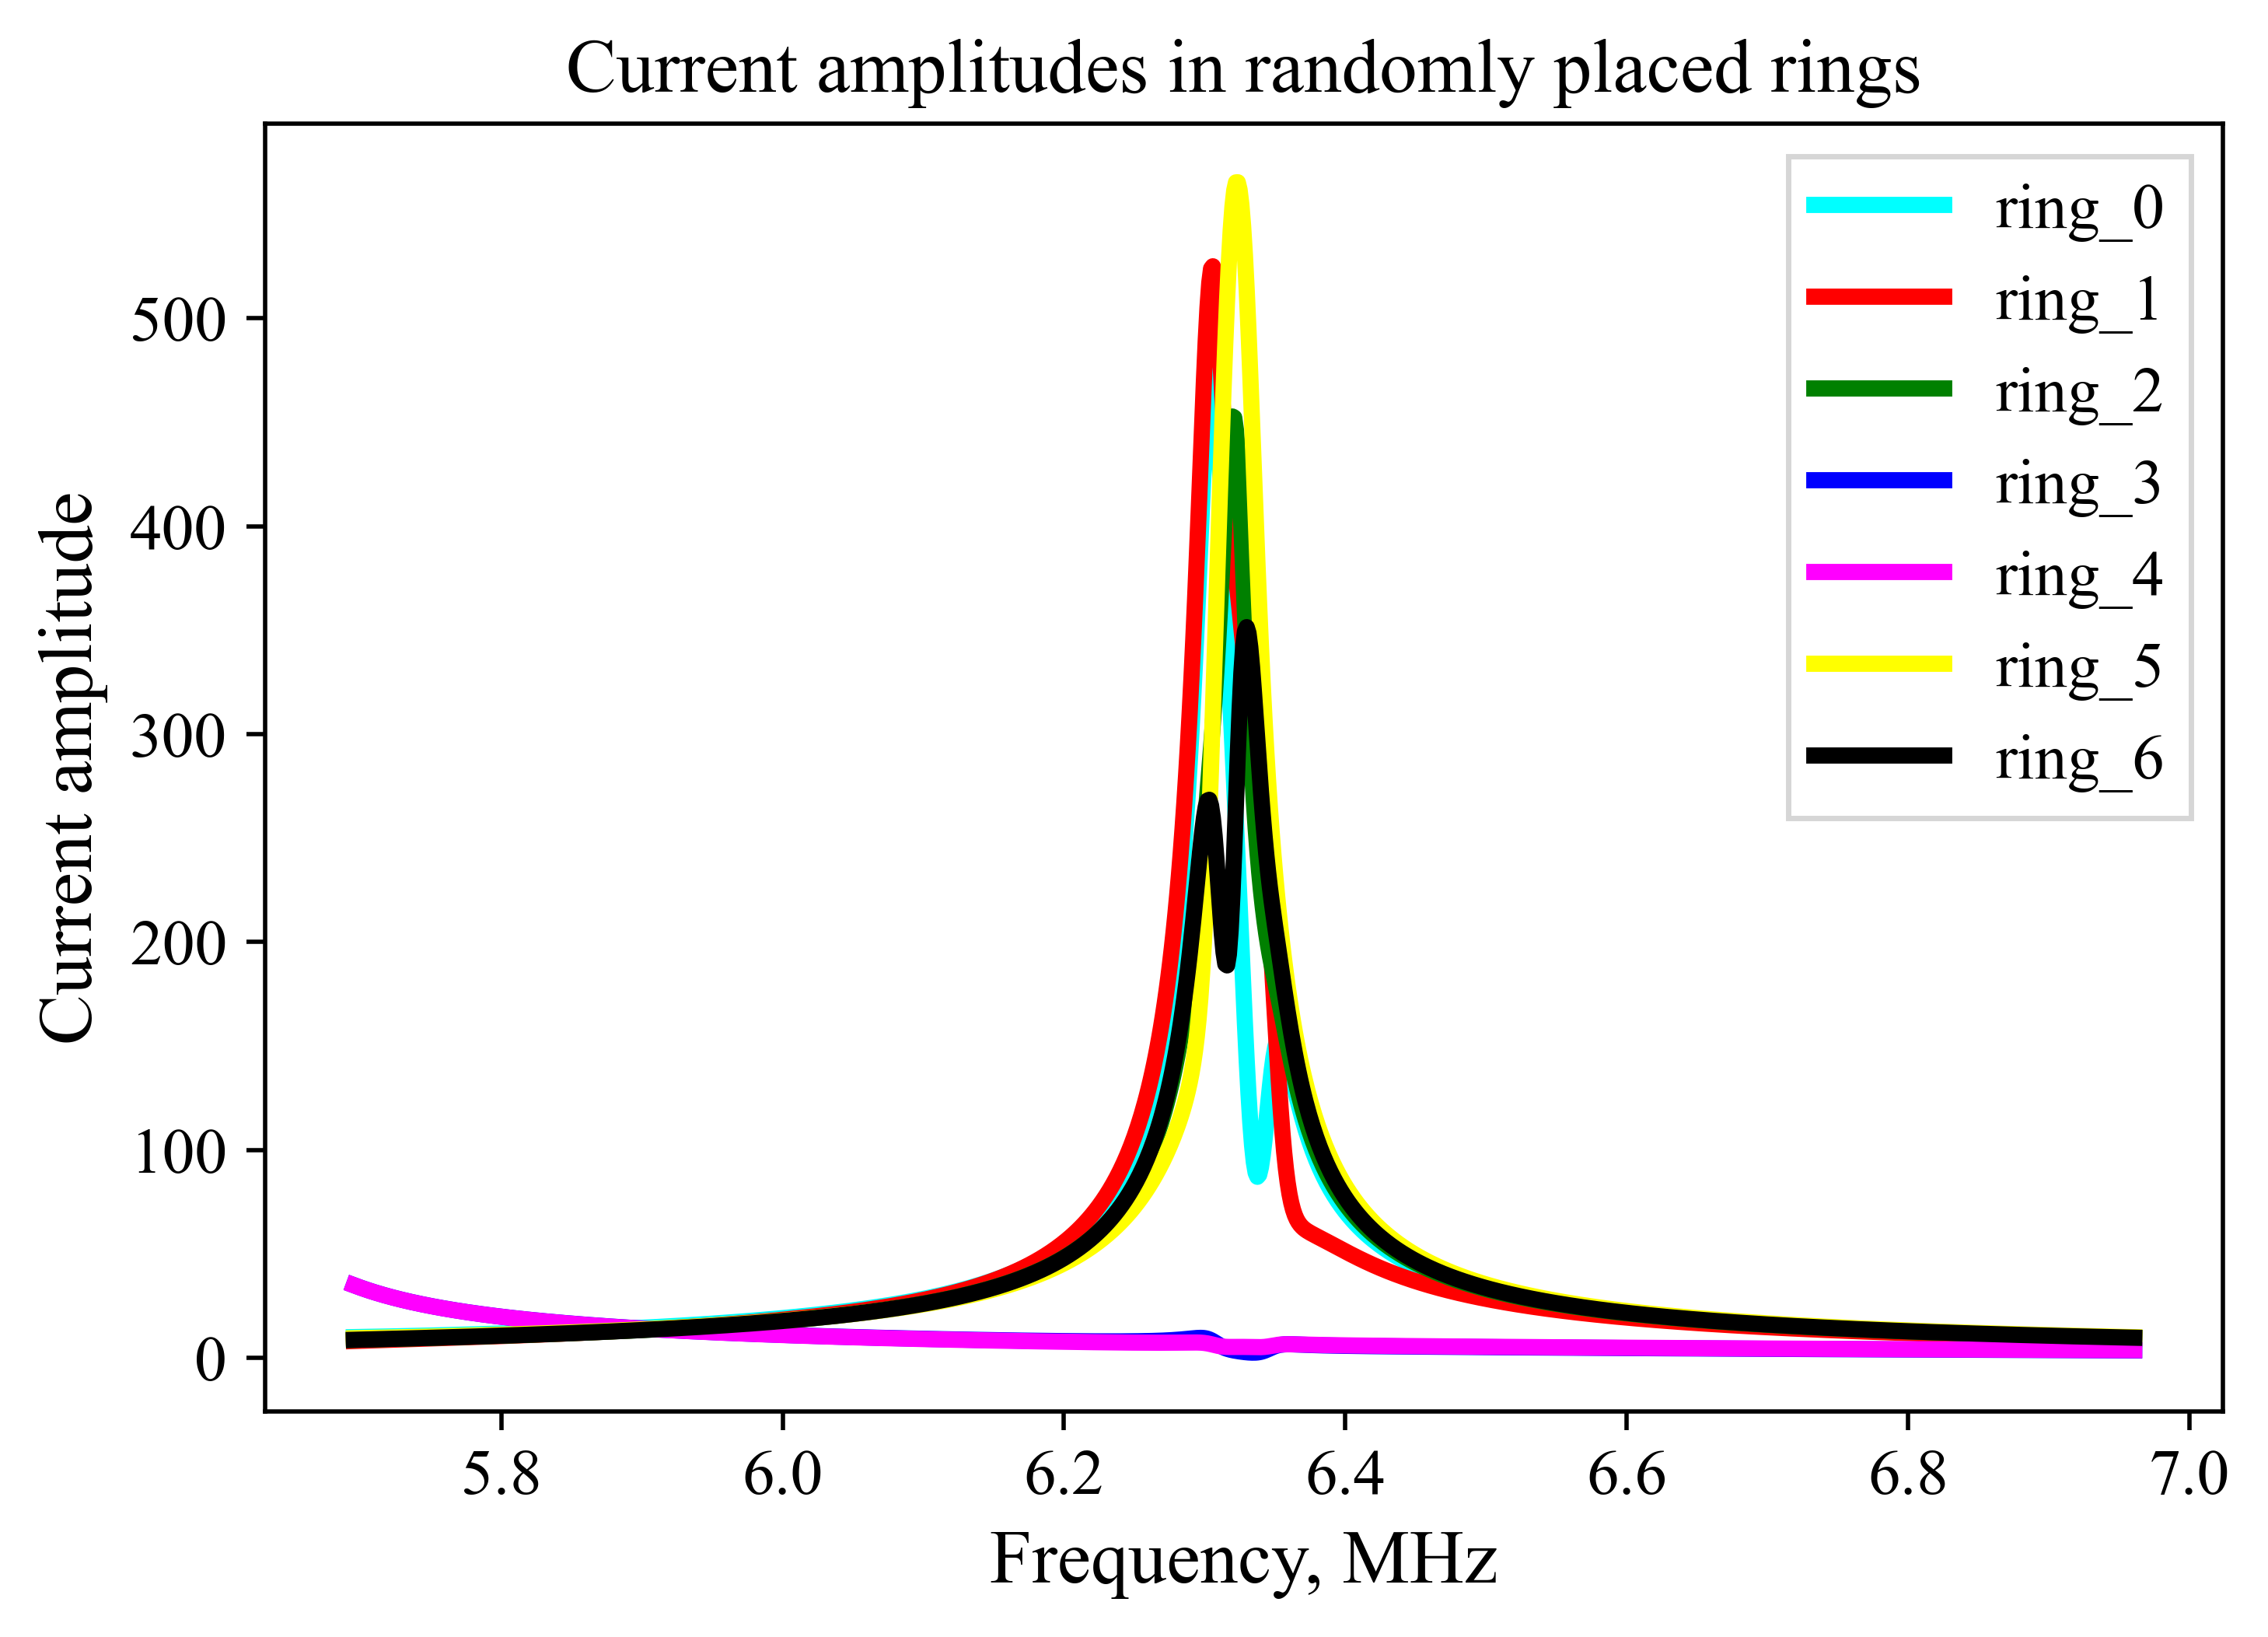

In [ ]:
solver = MetaSolver(Omega = Omega,
					Rings = rings)
print(solver.number, "rings in the solver")
# Create uniform excitation
U_z = np.ones(solver.number_z)
U_y = np.zeros(solver.number_y)
U_x = np.zeros(solver.number_x)
U = np.concatenate([U_z, U_y, U_x])
# Calculate solution on given frequency range
solution = solver.direct_solve(U)
# Save solution to folder './Data_Random'
solution.save_sol('./Data')
for i in range(len(rings)):
	plt.plot(solution.Omega/2/np.pi/1e6, np.abs(solution.currents[:, i]), label = f'ring_{i}')
plt.title('Current amplitudes in randomly placed rings')
plt.ylabel('Current amplitude')
plt.xlabel('Frequency, MHz')
plt.legend()
plt.show()

### Example 3: opening solved structure and plotting results

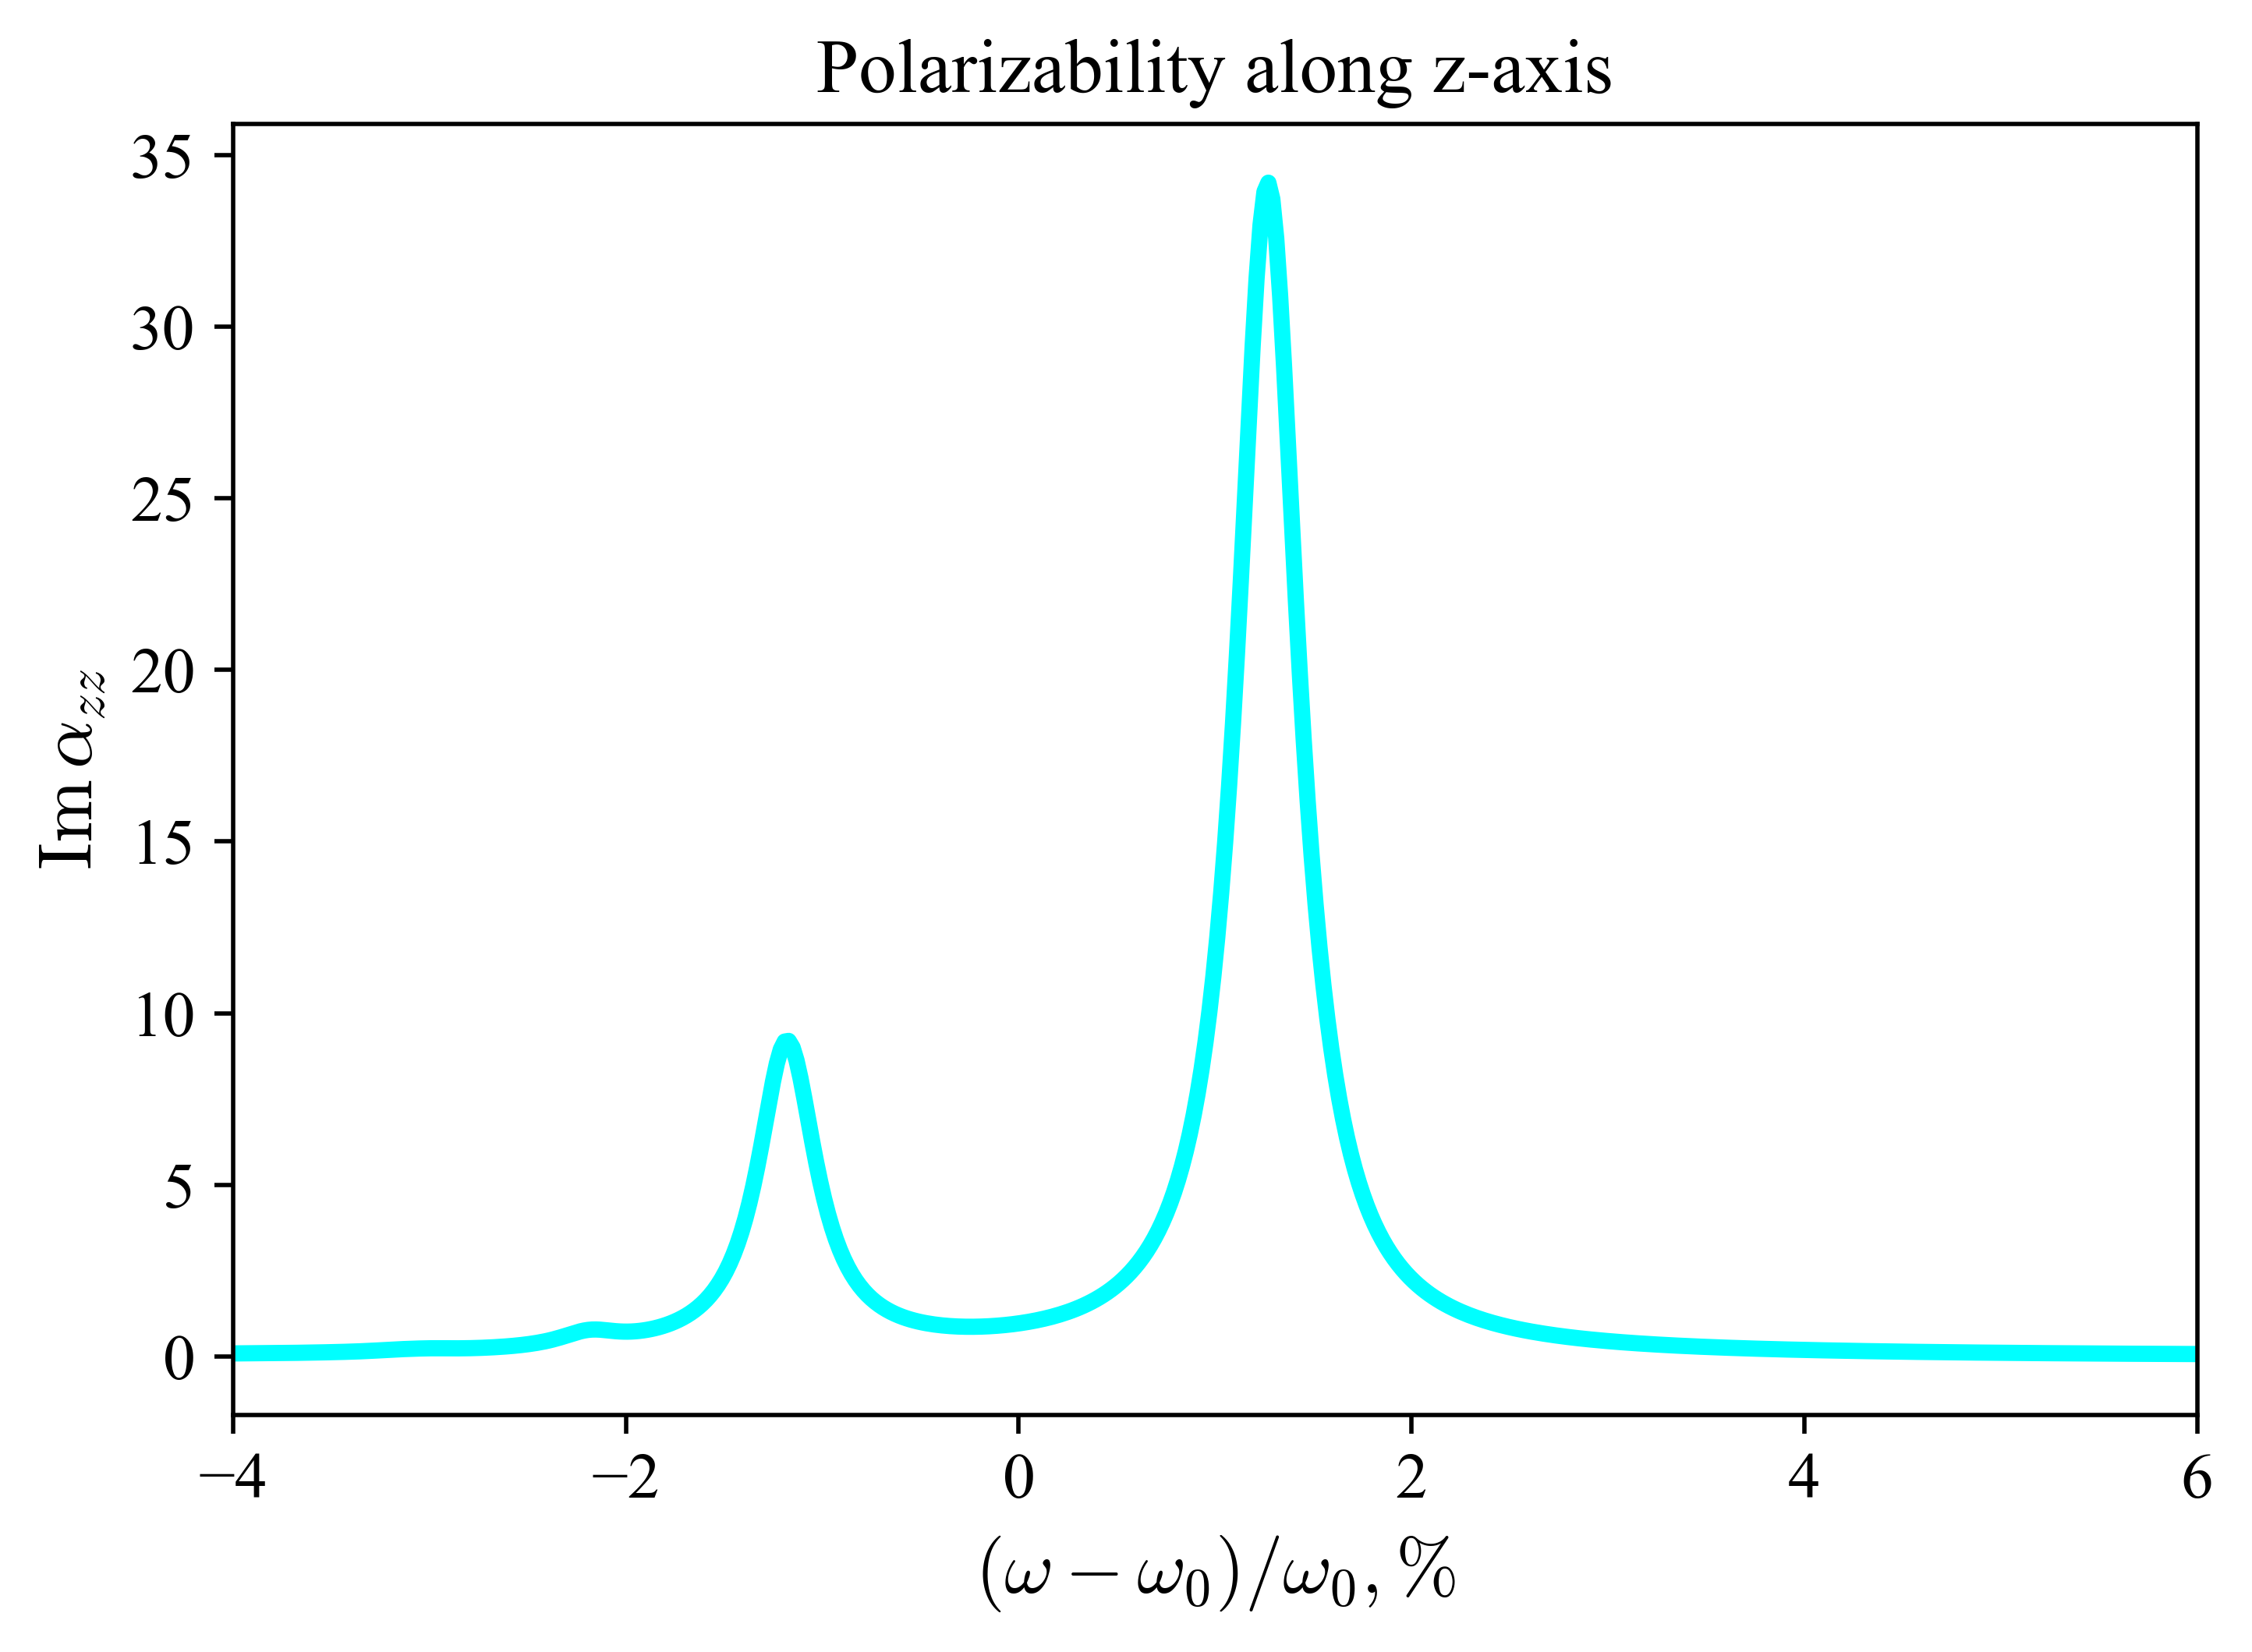

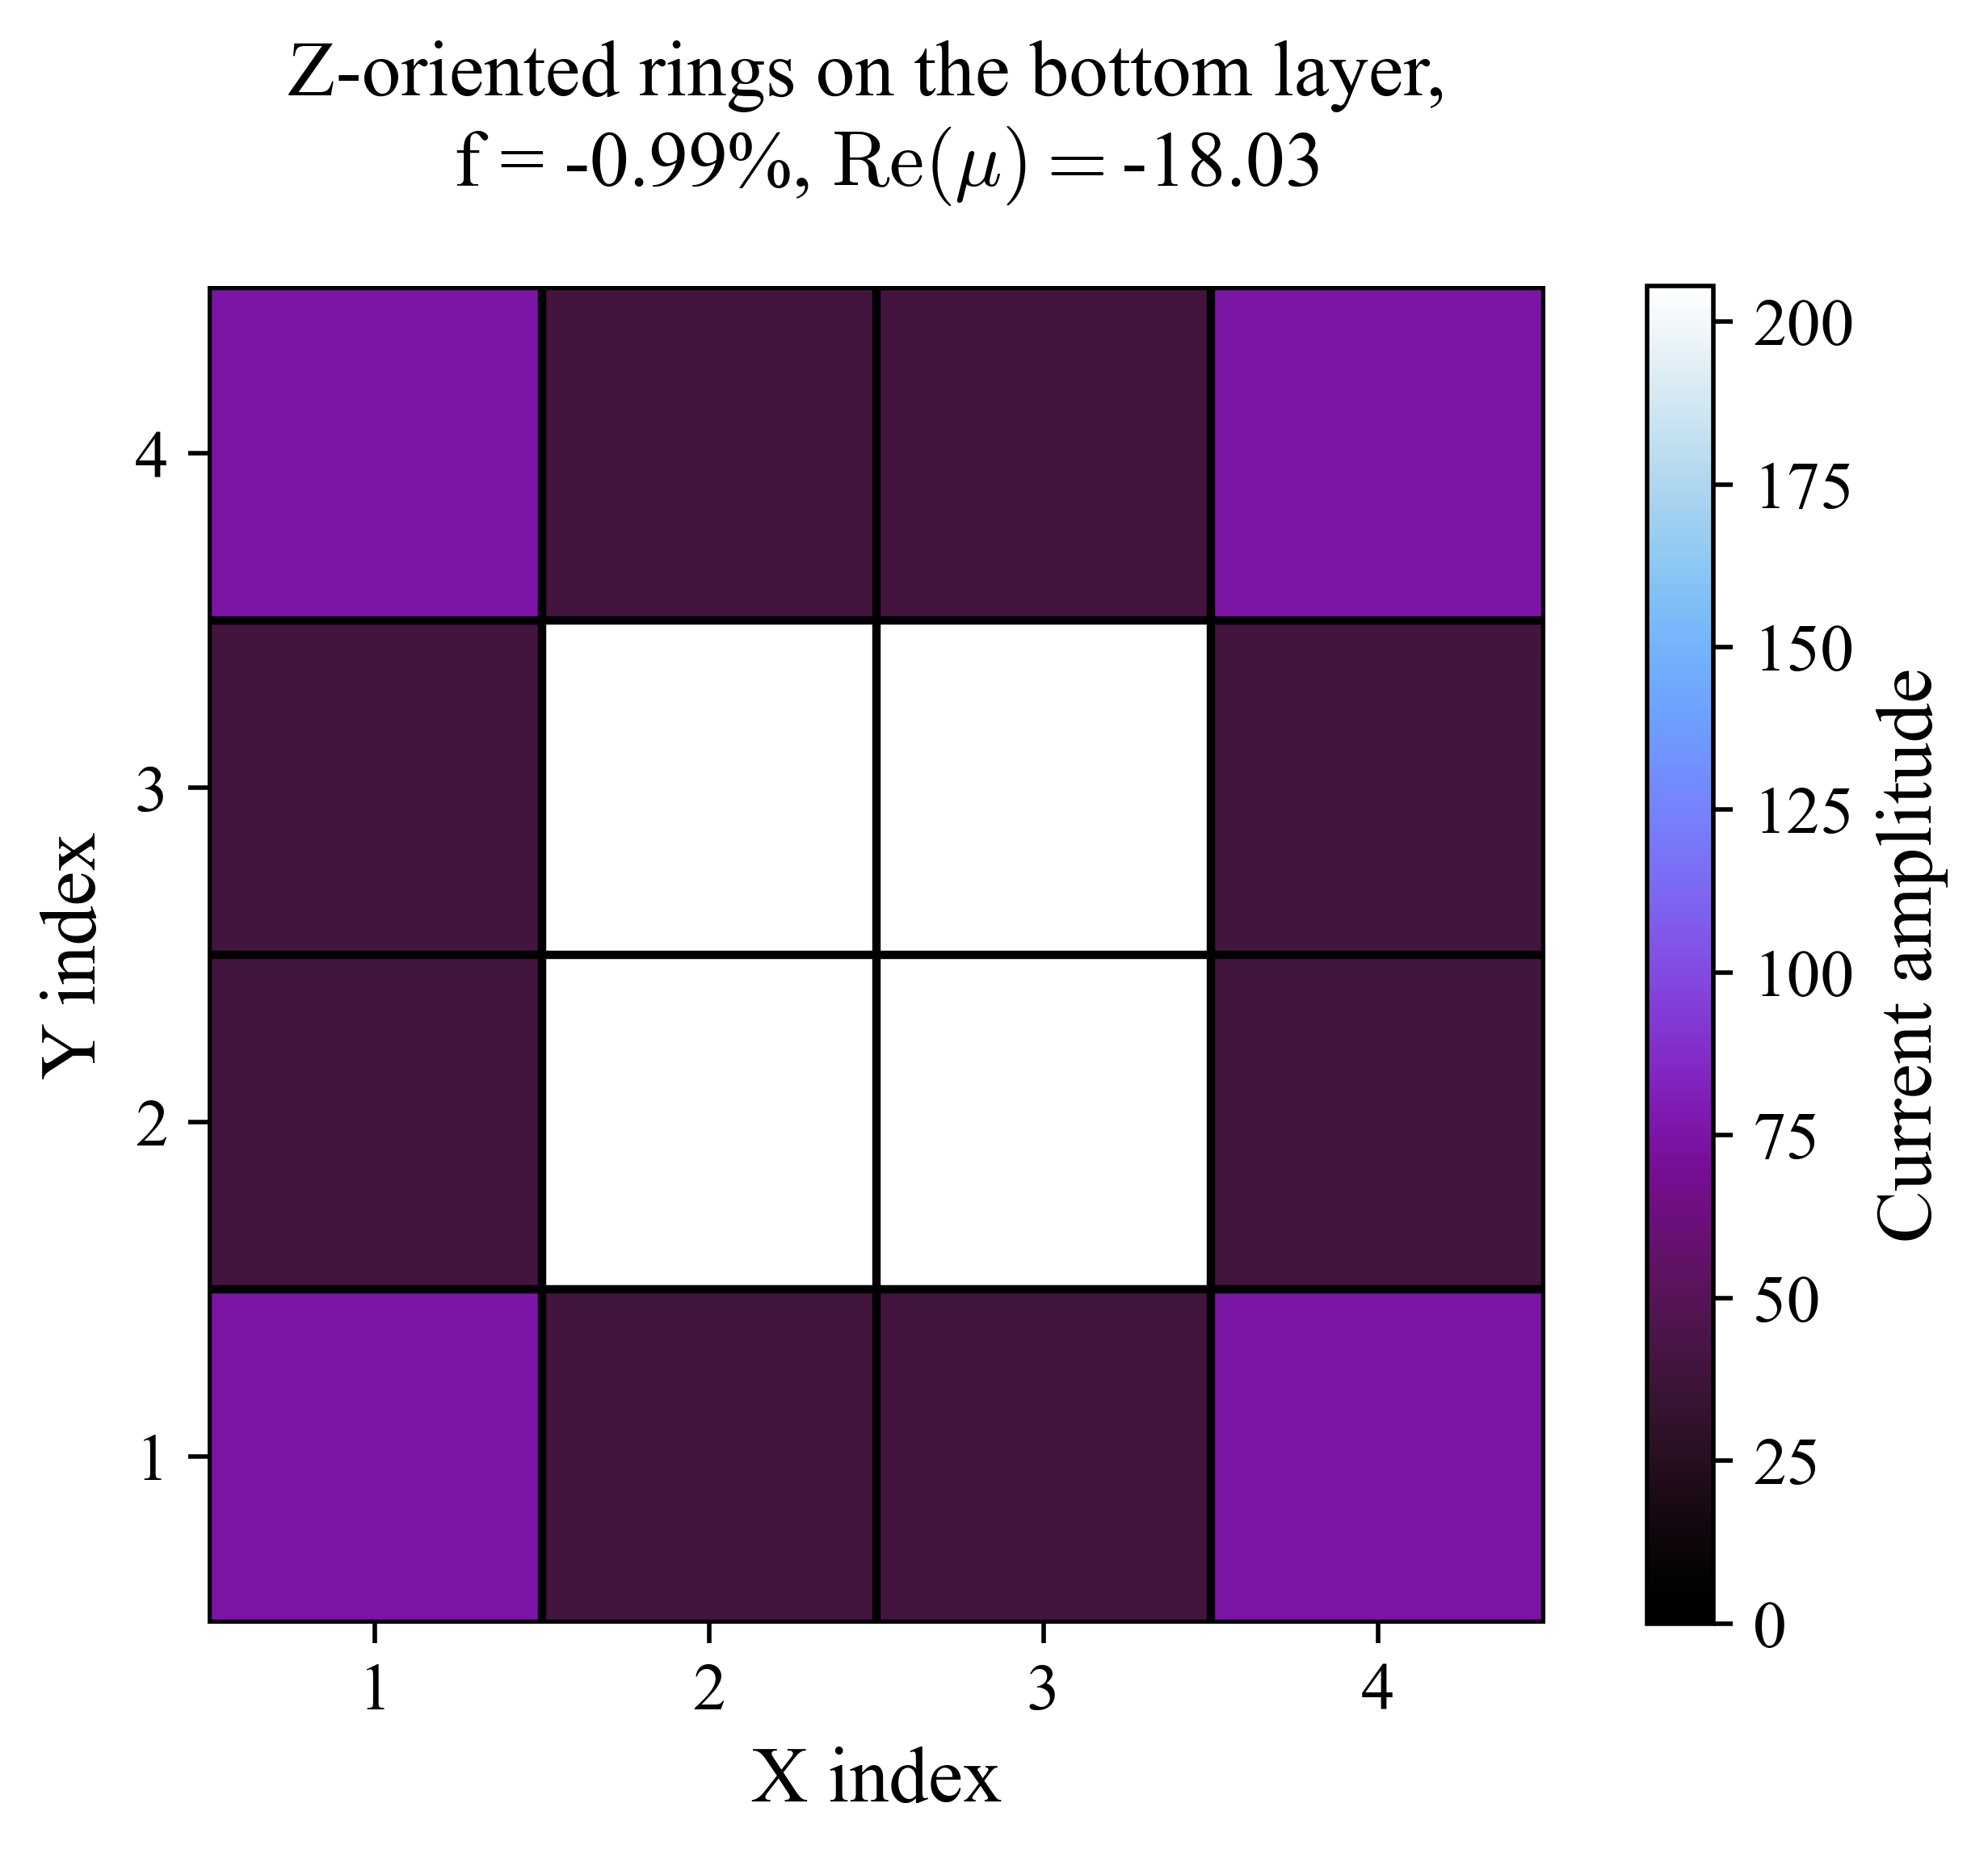

In [15]:
from Metastructure import Metastructure
from Solvers import MetaSolver, MetaSolution
# import default parameters for rings from file 
from Parameters import SRR, Omega

import numpy as np
import matplotlib.pyplot as plt
import colormaps as cmaps

nz, ny, nx = 4, 4, 4
Type = 'smooth'
geometry = 'rectangle'
MetaCube = Metastructure(metamaterial = SRR,	# Metaatom parameters
						 shape = (nz, ny, nx), 	# Size for uniform grid
						 geometry=geometry,  	# form of the structure
						 Type = Type 		# type of finite metastructure
)
MetaCube.fill_grid()
MetaCube.visualize()
solution, solution_polarizability = MetaSolution(), MetaSolution()
solution.open_sol(f'./Data', MetaCube, load_currents=True)
solution_polarizability.open_sol(f'./DataPolarizability', MetaCube, load_currents=False)

shape_z_oriented = (len(solution.Omega), MetaCube.N['z']['nz'], MetaCube.N['z']['ny'], MetaCube.N['z']['nx'])
currents_z0 = solution.currents[:, :MetaCube.numbers['z']]
currents_z0_4d = currents_z0.reshape(shape_z_oriented)
relative_frequency = (solution_polarizability.Omega - SRR.omega_0)/SRR.omega_0 * 100

# Plot polarizability along z-axis
alpha_zz = solution_polarizability.polarizability['z']
plt.plot(relative_frequency, np.imag(alpha_zz))
plt.title('Polarizability along z-axis')
plt.xlabel(r'$(\omega - \omega_0)/\omega_0, \%$')
plt.ylabel(r'$\operatorname{Im}\alpha_{zz}$')
plt.xlim(-4, 6)
plt.show()

# Plot current amplitudes in Z-oriented rings at some frequency
w_i = 450
plt.pcolormesh(np.abs(currents_z0_4d[w_i, 0, :, :]),
			   cmap=cmaps.voltage,
			   norm=plt.Normalize(vmin=0))
plt.axis('equal')
freq_i = round(relative_frequency[w_i], 2)
mu_i = round(SRR.effective_mu(solution_polarizability.Omega[w_i]).real,2)
plt.title(
	f'Z-oriented rings on the bottom layer, \n f = {freq_i}%, '+r'$\operatorname{Re}(\mu) = $' + f'{mu_i}', 
	y=1.05
)
x_values, y_values = np.arange(1, MetaCube.N['z']['nx']+1), np.arange(1, MetaCube.N['z']['ny']+1)
xticks, yticks = -0.5 + x_values, -0.5 + y_values
plt.xticks(xticks, x_values)
plt.yticks(yticks, y_values)
for x in np.arange(0, MetaCube.N['z']['nx']+1):
    plt.axvline(x, color = 'black', linewidth = 1.5, 
                ymin = 0, ymax = 50)
for y in np.arange(0, MetaCube.N['z']['ny']+1):
    plt.axhline(y, color = 'black', linewidth = 1.5,
                xmin = 0, xmax = 50)
for pos in ['top', 'right', 'bottom', 'left']:
	plt.gca().spines[pos].set_visible(False)
plt.gca().set_aspect(1, 'box')
plt.xlabel('X index')
plt.ylabel('Y index')
plt.colorbar(label = 'Current amplitude')
plt.show()